# 02 · Modelo de demanda: ¿cuánto venderá Kaido?

**Pregunta 2 del caso:** *"Construya un modelo de demanda mensual para cada segmento, con la economía, el calendario y el producto, y compruébelo con los datos de A012."*

### La idea
```
demanda Kaido = mercado × cuota de Kaido
```
El análisis muestra que conviene separar el mercado en dos piezas, por lo que el modelo final tiene **tres**:
```
demanda Kaido = mercado total × peso del segmento × cuota de Kaido
                (economía)      (gustos: SUV vs berlina)  (producto Kaido)
```

### Metodología de evaluación
Para todo el notebook usamos la **prueba con A012** (*backtest*): entrenamos con datos **hasta A011**, prevemos A012 y comparamos con lo que pasó. Es una evaluación fuera de muestra: el modelo no ha visto esos datos.

### Índice
1. Cómo medimos si un modelo es bueno
2. Elegir las variables económicas
3. Modelo del mercado total
4. Del mercado total a cada segmento
5. La cuota de Kaido
6. La demanda de Kaido: todo junto
7. ¿Se puede mejorar la cuota?
8. ¿Cuánto se equivoca? El error σ para la simulación
9. Conclusiones

## Decisiones de diseño

| # | Decisión | Elección | Dónde se ve |
|---|---|---|---|
| 1 | Qué prevemos | **Demanda limpia** (ventas − automatriculaciones) | Notebook 01 |
| 2 | Transformación | **Logaritmo**: las piezas se multiplican y en log se suman | §3 |
| 3 | Arquitectura del mercado | **SARIMAX**: admite variables externas → podremos simular escenarios | §3 |
| 4 | Datos de entrenamiento | **Desde A001**: las crisis enseñan cómo cae el mercado | §3 |
| 5 | Variables económicas | **2**, elegidas por datos y que muevan los escenarios | §2 |
| 6 | Retraso de las económicas | **3 meses**: lo que se conoce al decidir t+3 | §2 |
| 7 | Sucesos | Planes de ayuda e IVA como variables 0/1; **adelantos y caídas, fuera** | §3 |
| 8–10 | Cuota | Cuota limpia, método sencillo, casos especiales aparte | §5 |
| 11–13 | Evaluación | Contra el **modelo ingenuo**, error del total y mensual, σ por segmento | §1, §7 |

In [1]:
import sys, warnings
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datos import cargar, panel_segmento, macro, SEGMENTOS
from demanda import (exogenas, meses_evento, ajustar_mercado, prever_mercado, peso_segmento,
                     cuota_media, ingenuo, error_pct, mape, sigma_log,
                     SUCESOS_MODELO, EVENTOS_FUERA)
from graficos import (estilo, es, eje_miles, eje_fechas, anio_caso, guardar,
                      COLORES, NOMBRES, AZUL, ROJO, TINTA, TINTA_2, APAGADO, SUCESO, BANDA)

estilo()
d = cargar()
p = panel_segmento(d)
mac = macro(d)

# Series mensuales (columnas = segmentos)
mercado = p["mercado"].unstack("segmento").asfreq("MS")[SEGMENTOS]
demanda = p["demanda"].unstack("segmento").asfreq("MS")[SEGMENTOS]
cuota = demanda / mercado                       # cuota limpia
total = mercado.sum(axis=1)                     # mercado de los 7 segmentos

FIN = "2011-12-01"                              # entrenamos hasta A011
A012 = pd.date_range("2012-01-01", periods=12, freq="MS")
ENE_OCT = A012[:10]                             # A012 sin el adelanto de nov-dic

## 1. Cómo medimos si un modelo es bueno

**Tres ideas:**

1. **Prueba fuera de muestra.** Entrenar hasta A011 y prever los 12 meses de A012. Si evaluáramos con los mismos datos con los que entrenamos, cualquier modelo complicado parecería perfecto (sobreajuste).

2. **Dos medidas de error:**
   - **Error del total (%)** = previsto del año / real del año − 1. Dice si nos **pasamos** (+) o nos **quedamos cortos** (−). Es lo que más importa para fabricar.
   - **Error mensual medio (MAPE, %)** = media de |previsto / real − 1| mes a mes. Dice cuánto se equivoca cada mes.

3. **Un rival que batir: el modelo ingenuo.** *"Este mes se venderá lo mismo que el mismo mes del año pasado."* Si un modelo no gana a esto, no sirve.

**Ojo con noviembre y diciembre de A012:** llevan el adelanto de compras. Lo miraremos **aparte** (enero–octubre por un lado) para no confundir "el modelo es malo" con "pasó algo excepcional".

## 2. Elegir las variables económicas

**El problema:** hay 9 variables económicas. Con 12 años de datos, si metemos muchas el modelo **memoriza el pasado** (sobreajuste) y falla en el futuro. Queremos 2 o 3.

**Criterio de selección.** el consejo del enunciado, *comparar crecimientos con crecimientos*. Calculamos:
- el crecimiento interanual del mercado: log(mercado de este mes) − log(mercado del mismo mes del año anterior);
- el cambio interanual de cada variable;
- y su **correlación** (de −1 a 1: cuánto se mueven juntos), con la variable del **mismo mes** y con la de **hace 3 meses**.

Solo con datos de entrenamiento (A002–A011).

In [2]:
variables = ["confianza_consumidor", "paro", "tipo_credito_consumo", "hipotecas", "consumo_privado_var",
             "pib_var", "indice_actividad", "indice_comercio", "viajeros_var"]
crec_mercado = np.log(total) - np.log(total).shift(12)

corr = {}
for v in variables:
    x = mac[v].loc[:"2012-12-01"]
    cambio = x - x.shift(12)
    for retraso in [0, 3]:
        dfc = pd.concat([crec_mercado, cambio.shift(retraso)], axis=1).loc["2002":"2011"].dropna()
        corr[(v, f"retraso {retraso} meses")] = dfc.corr().iloc[0, 1]
corr = pd.Series(corr).unstack().sort_values("retraso 3 meses", key=abs, ascending=False)
corr.style.format(lambda x: es(x, 2)).background_gradient(cmap="RdBu", vmin=-1, vmax=1)

,retraso 0 meses,retraso 3 meses
confianza_consumidor,"0,55","0,61"
hipotecas,"0,65","0,47"
paro,"-0,48","-0,31"
consumo_privado_var,"0,60","0,25"
indice_comercio,"0,63","0,23"
tipo_credito_consumo,"0,08","0,17"
viajeros_var,"0,34","0,15"
pib_var,"0,47","0,14"
indice_actividad,"0,50","0,12"


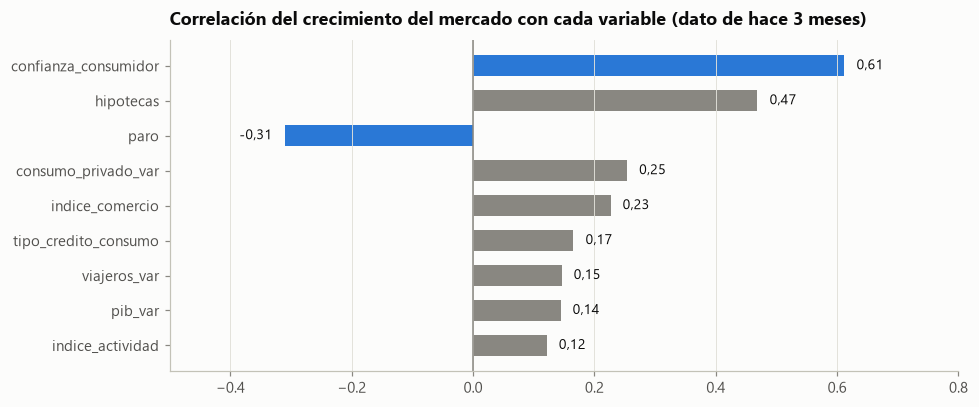

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
c3 = corr["retraso 3 meses"]
colores = [AZUL if v in ("confianza_consumidor", "paro") else APAGADO for v in c3.index]
ax.barh(c3.index[::-1], c3.values[::-1], color=colores[::-1], height=0.6)
ax.axvline(0, color=APAGADO, lw=1)
for i, v in enumerate(c3.values[::-1]):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, es(v, 2), va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-0.5, 0.8)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Correlación del crecimiento del mercado con cada variable (dato de hace 3 meses)")
fig.tight_layout()
guardar(fig, "10_correlacion_macro")

**Resultados y elección.**
- **Confianza del consumidor (0,61 con 3 meses de retraso):** la mejor, y **mejora con el retraso** (0,55 → 0,61). El enunciado ya lo decía: *"se adelanta unos meses"*. Si la gente está optimista, compra coche unos meses después.
- **Paro (−0,31 con retraso):** signo correcto (más paro → menos coches). Es la variable con la que la Tabla 4 define los escenarios (*"el paro sube dos puntos"*).
- **Hipotecas (0,47)** correla más que el paro, pero **no aparece en los escenarios**: no sabríamos cuánto moverla en el pesimista. Preferimos una variable algo menos correlada pero que podamos usar para simular. Es un *trade-off* consciente.
- **Tipo del crédito (0,17):** casi no se relaciona → fuera. El escenario optimista dice *"el crédito se abarata"*, pero el dato no muestra que eso mueva el mercado.
- Otras (comercio, consumo privado) correlan bien en el mismo mes pero **pierden casi todo con el retraso**: no nos sirven para decidir con 3 meses de antelación.

> **Elección: confianza del consumidor y paro, con el dato de hace 3 meses.** Dos variables, con sentido económico, que conocemos al decidir y que mueven los escenarios.

## 3. Modelo del mercado total

### ¿Qué es un SARIMAX? (en 4 líneas)
Trabajamos con log(mercado). El modelo dice:
- **S (estacional) + I (integrado):** compara cada mes con el **mismo mes del año anterior** (diferencia estacional). Así la estacionalidad desaparece sola.
- **X (variables externas):** ese crecimiento interanual se explica por los cambios en calendario, sucesos y economía.
- **ARMA:** lo que queda (el error) puede tener memoria de los meses anteriores.

Es el modelo del Anexo 4. Probamos tres versiones y las comparamos con el ingenuo y con la especificación exacta del Anexo 4.

In [4]:
X = exogenas(mac)                                          # calendario + ayuda + IVA + económicas (l3)
X_con_eventos = exogenas(mac, sucesos=SUCESOS_MODELO + EVENTOS_FUERA)
X_anexo4 = mac[["paro", "confianza_consumidor", "dias_laborables", "semana_santa"]]
eventos = meses_evento(mac)

intentos = {
    "Anexo 4 (tal cual)": (X_anexo4, None, (1, 0, 0)),
    "A. Adelanto y caída como variables 0/1": (X_con_eventos, None, (1, 0, 0)),
    "B. Adelanto y caída como dato que falta": (X, eventos, (1, 0, 0)),
    "C. Como B, con error MA(1) (elegido)": (X, eventos, (0, 0, 1)),
}
real = total[A012]
filas, prev_total = {}, {}
for nombre, (Xi, ev, orden) in intentos.items():
    mod = ajustar_mercado(total, Xi, FIN, eventos=ev, orden=orden)
    pr = prever_mercado(mod, Xi, A012)
    prev_total[nombre] = pr
    filas[nombre] = {"Error total A012 (%)": error_pct(real, pr),
                     "Error total ene–oct (%)": error_pct(real[ENE_OCT], pr[ENE_OCT]),
                     "MAPE ene–oct (%)": mape(real[ENE_OCT], pr[ENE_OCT])}
nv = ingenuo(total, A012)
prev_total["Ingenuo"] = nv
filas["Ingenuo (mismo mes año anterior)"] = {"Error total A012 (%)": error_pct(real, nv),
                                             "Error total ene–oct (%)": error_pct(real[ENE_OCT], nv[ENE_OCT]),
                                             "MAPE ene–oct (%)": mape(real[ENE_OCT], nv[ENE_OCT])}
pd.DataFrame(filas).T.style.format(lambda x: es(x, 1))

,Error total A012 (%),Error total ene–oct (%),MAPE ene–oct (%)
Anexo 4 (tal cual),"-6,7","-4,9","6,7"
A. Adelanto y caída como variables 0/1,"16,3","10,8","10,8"
B. Adelanto y caída como dato que falta,"4,0","5,2","6,2"
"C. Como B, con error MA(1) (elegido)","-1,0","0,9","4,7"
Ingenuo (mismo mes año anterior),"3,5","4,9","10,5"


**Resultados.**
- **El intento A se pasa un 16 %.** ¿Por qué? El adelanto de agosto de A011 y la caída de septiembre–diciembre de A011 están **justo al final** de los datos de entrenamiento. El modelo no sabe separar "caída puntual" de "nivel del mercado", y al quitar la caída en A012 lo dispara hacia arriba.
- **Solución (B y C): tratar esos meses como datos que faltan.** El SARIMAX funciona con un *filtro de Kalman*, que sabe "saltarse" meses sin dato y seguir. Así aprende la demanda **normal** y los adelantos los añadimos aparte, con su tamaño estimado (lo haremos en los escenarios).
- **El modelo C** se equivoca **menos de un 1 % en enero–octubre** y gana al ingenuo y al Anexo 4.

El gráfico muestra por qué se evalúa también enero–octubre por separado:

Noviembre-diciembre: el real supera al modelo en un 12,2 % -> es el tamaño del adelanto


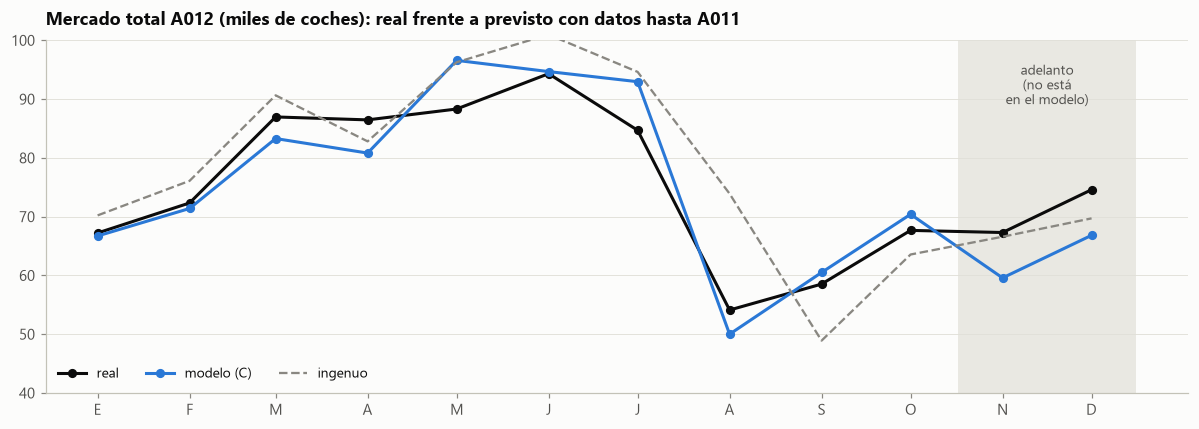

In [5]:
mod_total = ajustar_mercado(total, X, FIN, eventos=eventos, orden=(0, 0, 1))
pr = prev_total["C. Como B, con error MA(1) (elegido)"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.axvspan(pd.Timestamp("2012-10-17"), pd.Timestamp("2012-12-16"), color=BANDA, lw=0, zorder=0)
ax.text(pd.Timestamp("2012-11-16"), 96, "adelanto\n(no está\nen el modelo)", ha="center", va="top", fontsize=9, color=TINTA_2)
ax.plot(A012, real / 1000, color=TINTA, marker="o", ms=5, label="real")
ax.plot(A012, pr / 1000, color=AZUL, marker="o", ms=5, label="modelo (C)")
ax.plot(A012, nv / 1000, color=APAGADO, ls="--", lw=1.5, label="ingenuo")
ax.set_ylim(40, 100)
ax.set_xticks(A012, ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_title("Mercado total A012 (miles de coches): real frente a previsto con datos hasta A011")
ax.legend(loc="lower left", ncols=3)
fig.tight_layout()
guardar(fig, "11_backtest_mercado_total")

exceso = real["2012-11":"2012-12"].sum() / pr["2012-11":"2012-12"].sum() - 1
print(f"Noviembre-diciembre: el real supera al modelo en un {es(100 * exceso, 1)} % -> es el tamaño del adelanto")

**Resultados.** el modelo sigue muy bien la forma del año (el bache de agosto, la subida de marzo y junio). En **noviembre–diciembre** el real va un **≈12 %** por encima: es el **adelanto**, que no está en el modelo a propósito. El notebook 01 lo estimaba en ≈9 % con un método más tosco: las dos cifras cuadran.

### ¿Qué ha aprendido el modelo? Sus coeficientes
Como trabajamos en logaritmos, un coeficiente *b* significa que la variable multiplica el mercado por e^b. Lo traducimos a %:

In [6]:
coef = mod_total.params[mod_total.model.exog_names]
lectura = {
    "dias_laborables": "por cada día laborable más en el mes",
    "semana_santa": "si la Semana Santa cae ese mes",
    "incentivo_publico": "mientras hay plan público de ayuda",
    "subida_iva": "el mes antes de una subida del IVA",
    "confianza_consumidor_l3": "por cada punto más de confianza (hace 3 meses)",
    "paro_l3": "por cada punto más de paro (hace 3 meses)",
}
tabla_coef = pd.DataFrame({"efecto en el mercado (%)": 100 * (np.exp(coef) - 1),
                           "lectura": [lectura[k] for k in coef.index]})
tabla_coef.style.format({"efecto en el mercado (%)": lambda x: ("+" if x > 0 else "") + es(x, 1) + " %"})

,efecto en el mercado (%),lectura
dias_laborables,"+4,1 %",por cada día laborable más en el mes
semana_santa,"+1,5 %",si la Semana Santa cae ese mes
incentivo_publico,"+19,6 %",mientras hay plan público de ayuda
subida_iva,"+35,3 %",el mes antes de una subida del IVA
confianza_consumidor_l3,"+0,9 %",por cada punto más de confianza (hace 3 meses)
paro_l3,"-3,4 %",por cada punto más de paro (hace 3 meses)


**Todos los signos tienen sentido económico**, y eso da confianza:
- Un día laborable más → ≈ +4 % de matriculaciones (los concesionarios abren más días).
- Plan de ayuda → ≈ +20 %; mes antes de subir el IVA → ≈ +35 % (compras adelantadas).
- **Un punto más de paro → ≈ −3,4 % de mercado.** El escenario pesimista (*"el paro sube dos puntos"*) costará ≈ −7 % de mercado.

## 4. Del mercado total a cada segmento

### Primer intento: un SARIMAX para cada segmento
Lo natural: repetir el modelo C con el mercado de cada segmento.

In [7]:
pt = prever_mercado(mod_total, X, A012)
peso_prev = peso_segmento(mercado, FIN)

filas = {}
for s in SEGMENTOS:
    r = mercado[s][A012]
    mod_s = ajustar_mercado(mercado[s], X, FIN, eventos=eventos, orden=(0, 0, 1))
    pr_s = prever_mercado(mod_s, X, A012)
    pr_td = pt * peso_prev[s]
    filas[f"{s} · {NOMBRES[s]}"] = {
        "SARIMAX por segmento": error_pct(r[ENE_OCT], pr_s[ENE_OCT]),
        "Total × peso (elegido)": error_pct(r[ENE_OCT], pr_td[ENE_OCT]),
        "Ingenuo": error_pct(r[ENE_OCT], ingenuo(mercado[s], A012)[ENE_OCT]),
    }
comp = pd.DataFrame(filas).T
comp.loc["Error medio absoluto"] = comp.abs().mean()
comp.style.format(lambda x: es(x, 1)).set_caption("Error del total ene–oct A012 en el mercado de cada segmento (%)")

,SARIMAX por segmento,Total × peso (elegido),Ingenuo
MSUV · SUV medio,"-7,9","2,0","-2,5"
SSUV · SUV pequeño,"-36,4","3,6","-9,6"
C · Compacto,"36,4","-1,1","19,1"
B · Pequeño,"17,4","-1,8","12,4"
CSUV · SUV compacto,"-13,7","3,2","-5,0"
MD · Berlina media,"74,1","-0,6","48,0"
S · Descapotable,"-19,2","9,8","14,2"
Error medio absoluto,"29,3","3,2","15,8"


El SARIMAX por segmento **falla mucho**: compacto **+36 %**, berlina **+74 %**, SUV pequeño **−36 %**. En media se equivoca un 29 %, peor incluso que el ingenuo (16 %). ¿Qué está pasando?

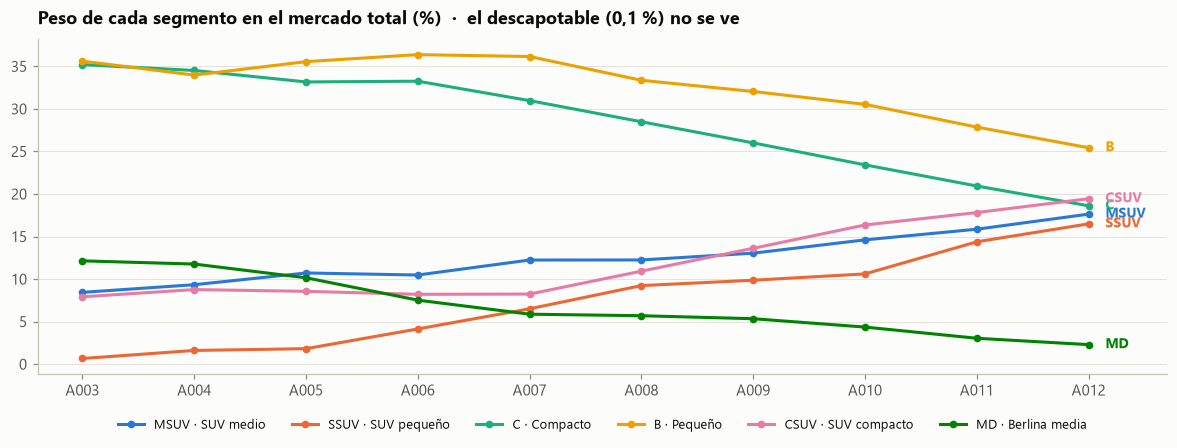

In [8]:
peso = mercado.div(total, axis=0)
peso_anual = 100 * peso.groupby(peso.index.year).mean().loc[2003:]

fig, ax = plt.subplots(figsize=(11, 4.2))
for s in SEGMENTOS:
    if s == "S":
        continue
    ax.plot(peso_anual.index, peso_anual[s], color=COLORES[s], marker="o", ms=4, label=f"{s} · {NOMBRES[s]}")
    ax.text(2012.15, peso_anual.loc[2012, s], s, color=COLORES[s], va="center", fontsize=9, fontweight="bold")
ax.set_xticks(peso_anual.index, [anio_caso(a) for a in peso_anual.index])
ax.set_xlim(2002.6, 2012.7)
ax.set_title("Peso de cada segmento en el mercado total (%)  ·  el descapotable (0,1 %) no se ve")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=6, fontsize=8.5)
fig.tight_layout()
guardar(fig, "12_peso_segmentos")

**La "SUVización" del mercado.** Desde A006 los SUV (compacto, medio y pequeño) ganan peso año tras año y el pequeño, el compacto y la berlina lo pierden. En A012: el mercado total cae −3 %, pero el SUV pequeño crece +11 % y la berlina cae −29 %.

El SARIMAX de cada segmento ve el crecimiento de A011 y lo prolonga, pero no sabe que **es un trasvase entre segmentos**, no un mercado que crece.

### Solución: dos piezas separadas
```
mercado del segmento = mercado total × peso del segmento
```
- El **mercado total** depende de la economía → el SARIMAX del §3 (que funciona muy bien).
- El **peso** depende de los gustos y cambia despacio y con tendencia → regla sencilla:

```
peso previsto = peso medio del último año × (tendencia anual media de los dos últimos años)
```
y al final se **reescalan para que sumen 100 %** (si no, al proyectar cada segmento por su lado, la suma se va al 102–103 % y se inventan coches).

Probamos varias reglas y nos quedamos con **una sola para todos los segmentos**. Elegir una regla distinta para cada segmento mirando A012 supondría sobreajustar al periodo de prueba.

In [9]:
def reglas_peso(fin):
    w = mercado.div(total, axis=0).loc[:fin]
    ult, ant, hace2 = w.iloc[-12:].mean(), w.iloc[-24:-12].mean(), w.iloc[-36:-24].mean()
    norm = lambda w: w / w.sum()           # los pesos tienen que sumar 100 %
    return {"Sin tendencia (peso último año)": norm(ult),
            "Tendencia del último año": norm(ult * (ult / ant)),
            "Tendencia media de 2 años (elegida)": norm(ult * (ult / hace2) ** 0.5)}

filas = {}
for nombre, w in reglas_peso(FIN).items():
    errs = {s: error_pct(mercado[s][ENE_OCT], (pt * w[s])[ENE_OCT]) for s in SEGMENTOS}
    errs["Error medio absoluto"] = np.mean(np.abs(list(errs.values())))
    errs["Peor segmento"] = max(np.abs(list(errs.values())[:-1]))
    filas[nombre] = errs
pd.DataFrame(filas).T.style.format(lambda x: es(x, 1)).set_caption("Error del total ene–oct A012 por segmento (%)")

,MSUV,SSUV,C,B,CSUV,MD,S,Error medio absoluto,Peor segmento
Sin tendencia (peso último año),"-5,3","-12,1","12,9","7,9","-7,6","34,8","5,9","12,3","34,8"
Tendencia del último año,"0,3","16,3","-1,6","-3,9","-1,8","-8,1","-15,1","6,7","16,3"
Tendencia media de 2 años (elegida),"2,0","3,6","-1,1","-1,8","3,2","-0,6","9,8","3,2","9,8"


**Resultados.** sin tendencia, la berlina se pasa un 35 % (no ve que el segmento se hunde). Con la tendencia de un solo año, el SUV pequeño se pasa un 16 % (A011 fue un año de salto excepcional y lo prolonga). **La media de dos años es la más equilibrada:** ningún segmento grande se desvía más de un 4 %.

## 5. La cuota de Kaido

**Qué es:** cuota limpia = demanda limpia de Kaido / mercado del segmento. Depende del **producto** (renovaciones, coches nuevos, precio, descuentos), no de la economía.

In [10]:
cuota_anual = 100 * (demanda.groupby(demanda.index.year).sum() / mercado.groupby(mercado.index.year).sum()).loc[2008:]
cuota_anual.index = [anio_caso(a) for a in cuota_anual.index]
cuota_anual.columns = [f"{s} · {NOMBRES[s]}" for s in cuota_anual.columns]
cuota_anual.T.style.format(lambda x: es(x, 2)).set_caption("Cuota limpia anual de Kaido (%)")

,A008,A009,A010,A011,A012
MSUV · SUV medio,"7,64","6,41","5,35","5,64","4,73"
SSUV · SUV pequeño,"2,51","5,43","4,69","3,75","3,77"
C · Compacto,"1,44","1,47","1,72","1,67","2,20"
B · Pequeño,"0,45","0,53","0,42","0,58","0,70"
CSUV · SUV compacto,"0,00","0,00","0,00","0,00","0,68"
MD · Berlina media,"4,42","4,14","3,58","3,53","2,88"
S · Descapotable,"43,73","43,09","54,03","47,87","60,77"


**Resultados.** la cuota es bastante estable en la mayoría, pero hay saltos ligados al producto. El más importante: el **SUV medio cae del 5,6 % al 4,7 %** en A012 (y la berlina del 3,5 % al 2,9 %). Es el segmento estrella y va perdiendo tirón. En A013 recibe **2 códigos nuevos** (renovación), que podrían recuperarlo.

Probamos tres métodos sencillos (el SUV compacto no se puede probar: no existía en A011):

In [11]:
filas = {}
for s in SEGMENTOS:
    if s == "CSUV":
        continue
    r = cuota[s][ENE_OCT]
    metodos = {
        "Media últimos 12 meses (elegida)": pd.Series(cuota_media(cuota[s], FIN, 12), index=ENE_OCT),
        "Media últimos 6 meses": pd.Series(cuota_media(cuota[s], FIN, 6), index=ENE_OCT),
        "Mismo mes año anterior": cuota[s].shift(12)[ENE_OCT],
    }
    filas[f"{s} · {NOMBRES[s]}"] = {k: mape(r, v) for k, v in metodos.items()}
tc = pd.DataFrame(filas).T
tc.loc["Media"] = tc.mean()
tc.style.format(lambda x: es(x, 1)).set_caption("Error mensual medio de la cuota, ene–oct A012 (%)")

,Media últimos 12 meses (elegida),Media últimos 6 meses,Mismo mes año anterior
MSUV · SUV medio,"29,7","32,3","25,4"
SSUV · SUV pequeño,"13,1","19,1","12,3"
C · Compacto,"52,4","52,6","53,7"
B · Pequeño,"28,6","37,6","18,2"
MD · Berlina media,"47,5","63,4","51,9"
S · Descapotable,"27,9","28,7","34,2"
Media,"33,2","38,9","32,6"


**Resultados.** el error mensual de la cuota es grande (la venta de Kaido en un mes es un número pequeño y salta mucho). La **media de 12 meses** y el **mismo mes del año anterior** empatan (≈33 %). Elegimos la media: no arrastra el ruido de un único mes del año anterior y es la más sencilla de explicar. Ningún método sencillo puede adivinar un cambio de producto como la caída del SUV medio: eso lo tratamos en los **escenarios** (*"los códigos nuevos se venden mejor/peor de lo previsto"*).

> **Conclusión:** el mercado se prevé bien (error < 1 %). **La incertidumbre de verdad está en la cuota**, en el producto de Kaido.

## 6. La demanda de Kaido: todo junto

```
demanda prevista = mercado total previsto × peso del segmento × cuota media 12 meses
```

In [12]:
prev_dem, filas = {}, {}
for s in SEGMENTOS:
    if s == "CSUV":
        continue
    pr = pt * peso_prev[s] * cuota_media(cuota[s], FIN)
    prev_dem[s] = pr
    r = demanda[s][A012]
    nv = ingenuo(demanda[s], A012)
    filas[f"{s} · {NOMBRES[s]}"] = {
        "Real A012": r.sum(), "Previsto A012": pr.sum(),
        "Error total (%)": error_pct(r, pr),
        "Error ene–oct (%)": error_pct(r[ENE_OCT], pr[ENE_OCT]),
        "Ingenuo: error ene–oct (%)": error_pct(r[ENE_OCT], nv[ENE_OCT]),
    }
td = pd.DataFrame(filas).T
td.style.format({"Real A012": es, "Previsto A012": es}).format(
    lambda x: es(x, 1), subset=["Error total (%)", "Error ene–oct (%)", "Ingenuo: error ene–oct (%)"])

,Real A012,Previsto A012,Error total (%),Error ene–oct (%),Ingenuo: error ene–oct (%)
MSUV · SUV medio,7.481,8.747,"16,9","30,1","18,0"
SSUV · SUV pequeño,5.635,5.845,"3,7","6,4","-16,8"
C · Compacto,3.696,2.810,"-24,0","-11,4","8,7"
B · Pequeño,1.623,1.419,"-12,6","-8,3","-5,2"
MD · Berlina media,591,766,"29,5","27,1","66,3"
S · Descapotable,488,439,"-10,1","-8,8","-11,6"


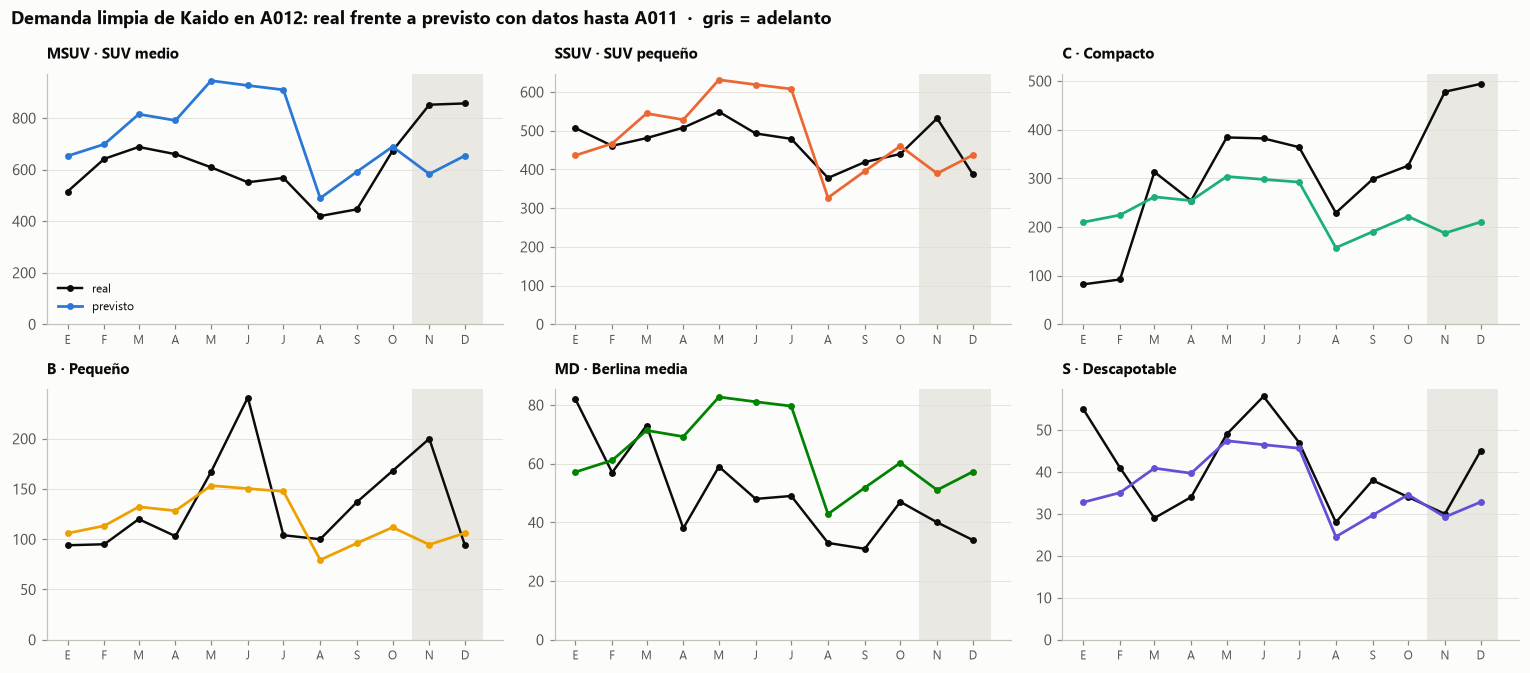

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.2))
for ax, s in zip(axes.flat, [s for s in SEGMENTOS if s != "CSUV"]):
    ax.axvspan(pd.Timestamp("2012-10-17"), pd.Timestamp("2012-12-16"), color=BANDA, lw=0, zorder=0)
    ax.plot(A012, demanda[s][A012], color=TINTA, marker="o", ms=3.5, lw=1.6, label="real")
    ax.plot(A012, prev_dem[s], color=COLORES[s], marker="o", ms=3.5, lw=1.8, label="previsto")
    ax.set_title(f"{s} · {NOMBRES[s]}", fontsize=10)
    ax.set_xticks(A012, ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"], fontsize=8)
    ax.set_ylim(0, None)
    eje_miles(ax)
axes[0, 0].legend(loc="lower left", fontsize=8)
fig.suptitle("Demanda limpia de Kaido en A012: real frente a previsto con datos hasta A011  ·  gris = adelanto",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "13_backtest_demanda_segmentos")

**Resultados.**
- **SUV pequeño, pequeño, compacto y descapotable:** dentro de ±12 % en enero–octubre. Aceptable para una previsión a 12 meses.
- **SUV medio (+30 %) y berlina (+27 %):** nos pasamos. No es culpa del mercado (que se prevé bien), sino de la **cuota**: Kaido perdió cuota en esos dos segmentos en A012.
- Frente al ingenuo, en el error del total el modelo gana en 3 segmentos (SUV pequeño, berlina, descapotable), pierde por poco en 2 (compacto y pequeño, 3 puntos) y pierde claramente en el SUV medio. Pero además **explica por qué** (economía, calendario, gustos, producto), que es lo que permite simular escenarios. El ingenuo no puede responder a *"¿y si el paro sube dos puntos?"*.

**¿Es un problema el +30 % del SUV medio?** En la vida real, no tanto: el plan **rueda**. Cada mes se actualiza la cuota con los datos reales, y tras dos o tres meses flojos la previsión se corrige sola. Por eso, para la simulación, separamos el error en dos partes.

## 7. ¿Se puede mejorar la cuota? Alternativas evaluadas

La cuota es la pieza débil. Probamos tres ideas:

| Idea | Qué hace |
|---|---|
| **A. Medir como se usa** | En el plan que rueda no se prevé a 12 meses: cada mes se actualiza todo y se prevé **a 3 meses vista**. Medimos el error así |
| **B. Más peso a lo reciente** | Suavizado exponencial: cada mes pesa α y lo anterior (1−α). Reacciona antes a cambios |
| **C. Reiniciar tras una renovación** | Media solo desde el último cambio de código (entre 3 y 12 meses) |
| **D. Más historia** | Media de 24 o 36 meses en vez de 12 |

### Protocolo de validación
Si se prueban muchos métodos y se elige el que mejor acierta A012, el error en A012 deja de ser una medida fiable: es el **sobreajuste del backtest**.

Por eso:
1. **Elegimos** con A010 y A011 (cada mes, prevista 3 meses antes con los datos de entonces).
2. **Confirmamos** con A012, una sola vez.

In [14]:
from demanda import cuota_exponencial, cuota_desde_renovacion, mercado_rodante

renov = p["renovacion_gama"].unstack("segmento").asfreq("MS")[SEGMENTOS]
segs = [s for s in SEGMENTOS if s != "CSUV"]

def evaluar_cuota(objetivos, h=3):
    filas = {}
    for s in segs:
        prev = {"Ingenuo (mismo mes año anterior)": [], "Media 12 meses (actual)": [], "Media 24 meses": [], "Media 36 meses": [],
                "Exponencial α=0,1": [], "Exponencial α=0,3": [], "Exponencial α=0,5": [], "Desde renovación": []}
        for f in objetivos:
            t = f - pd.DateOffset(months=h)          # lo que se sabía 3 meses antes
            prev["Ingenuo (mismo mes año anterior)"].append(cuota[s].shift(12).loc[f])
            prev["Media 12 meses (actual)"].append(cuota_media(cuota[s], t, 12))
            prev["Media 24 meses"].append(cuota_media(cuota[s], t, 24))
            prev["Media 36 meses"].append(cuota_media(cuota[s], t, 36))
            for a in (0.1, 0.3, 0.5):
                prev[f"Exponencial α={es(a, 1)}"].append(cuota_exponencial(cuota[s], t, a))
            prev["Desde renovación"].append(cuota_desde_renovacion(cuota[s], renov[s], t))
        filas[s] = {k: mape(cuota[s][objetivos], pd.Series(v, index=objetivos)) for k, v in prev.items()}
    t = pd.DataFrame(filas).T
    t.loc["MEDIA"] = t.mean()
    return t

seleccion = evaluar_cuota(pd.date_range("2010-01-01", "2011-12-01", freq="MS"))
confirmacion = evaluar_cuota(A012)
pd.concat({"1. Elegir: A010–A011": seleccion.loc[["MEDIA"]], "2. Confirmar: A012": confirmacion.loc[["MEDIA"]]}) \
  .droplevel(1).style.format(lambda x: es(x, 1)).set_caption("Error mensual medio de la cuota a 3 meses vista (%)")

,Ingenuo (mismo mes año anterior),Media 12 meses (actual),Media 24 meses,Media 36 meses,"Exponencial α=0,1","Exponencial α=0,3","Exponencial α=0,5",Desde renovación
1. Elegir: A010–A011,"33,1","26,9","27,8","26,8","26,4","28,2","28,9","29,4"
2. Confirmar: A012,"35,7","33,9","32,1","33,8","33,9","35,6","35,7","39,7"


**Resultados (ideas B y C).** ningún método gana de forma clara. En la selección, la media de 12 meses y la exponencial suave (α = 0,1) empatan (≈ 26–27 %); reaccionar más rápido (α alto) o reiniciar tras las renovaciones **empeora**: se persigue el ruido. **Más historia (24–36 meses) tampoco ayuda**: la cuota de hace 2–3 años es de coches que ya se han renovado, y en el error anual de la demanda empeora (A012: 17 % con 12 meses, 19 % con 24, 23 % con 36). En A012 se confirma: la media de 12 meses sigue entre las mejores.

**¿Y frente al ingenuo?** Usada como en el plan (a 3 meses vista), la media de 12 meses **gana al ingenuo en los dos periodos**: 26,9 % frente a 33,1 % en A010–A011 y 33,9 % frente a 35,7 % en A012. En el error anual de la demanda, 5,3 % frente a 8,2 % y 17,4 % frente a 18,2 %. La ventaja es clara en la selección y pequeña en A012.

> **Nos quedamos con la media de 12 meses.** Gana al ingenuo y, entre los métodos que empatan, es el más sencillo (navaja de Ockham).

**Idea A: ¿mejora el error de la demanda al prever a 3 meses vista?**

In [15]:
pt3 = mercado_rodante(mod_total, total, X, eventos, A012, h=3)
filas = {}
for s in segs:
    r = demanda[s][ENE_OCT]
    p12 = prev_dem[s][ENE_OCT]
    c3 = pd.Series({f: cuota_media(cuota[s], f - pd.DateOffset(months=3)) for f in A012})
    p3 = (pt3 * peso_prev[s] * c3)[ENE_OCT]
    filas[f"{s} · {NOMBRES[s]}"] = {"Error total, 12 meses vista (%)": error_pct(r, p12),
                                    "Error total, 3 meses vista (%)": error_pct(r, p3)}
pd.DataFrame(filas).T.style.format(lambda x: es(x, 1)).set_caption("Demanda Kaido ene–oct A012")

,"Error total, 12 meses vista (%)","Error total, 3 meses vista (%)"
MSUV · SUV medio,"30,1","27,4"
SSUV · SUV pequeño,"6,4","8,0"
C · Compacto,"-11,4","-15,7"
B · Pequeño,"-8,3","-7,6"
MD · Berlina media,"27,1","30,6"
S · Descapotable,"-8,8","-7,1"


**Resultados (idea A).** casi igual. Dos razones:
- **El mercado no mejora**: la memoria del modelo es de un mes (el término MA(1)); a 3 meses vista, lo que pesa es la estacionalidad y la economía, que ya se conocían.
- **La cuota tampoco**: la media de 12 meses tarda en olvidar A011. El SUV medio perdió cuota en enero y siguió bajo todo el año; la media se fue ajustando muy despacio.

### Conclusión del §7
**Ninguna de las cuatro ideas mejora la cuota.** Y eso **también es un resultado**: el error de la cuota no es un problema de método estadístico, es:
1. **ruido** (pocos coches al mes por segmento), que no se puede quitar, y
2. **cambios de producto** (la caída del SUV medio), que no están en los datos de ventas.

Lo segundo solo se arregla con **información del negocio** (planes de lanzamiento, precios, campañas). En el caso entra por los **escenarios** (*"los códigos nuevos se venden mejor/peor"*) y por el **plan que rueda**, que vigila la cuota cada mes como señal de alarma.

## 8. ¿Cuánto se equivoca? El error σ para la simulación

En la simulación, la demanda real de cada mes será `demanda prevista × e^ε`, con un error ε al azar. ¿Qué forma tiene ese error? Lo miramos en log (0,10 ≈ 10 %) y lo separamos en dos piezas:

```
error del mes = sesgo (igual todo el año)  +  ruido (distinto cada mes)
```

- **Sesgo:** el modelo se pasa o se queda corto **todo el año a la vez** (como el SUV medio, por la cuota). Es lo peligroso: no se compensa entre meses, y el colchón SS = z·σ·√3 lo infravalora (supone errores independientes). El plan que rueda lo va corrigiendo.
- **Ruido:** lo que sube un mes y baja el siguiente. Se compensa solo.

In [16]:
filas = {}
for s, pr in prev_dem.items():
    e = np.log(demanda[s][ENE_OCT] / pr[ENE_OCT])
    filas[f"{s} · {NOMBRES[s]}"] = {
        "Demanda media mensual": demanda[s][ENE_OCT].mean(),
        "Sesgo (log)": e.mean(),
        "Ruido σ (log)": e.std(ddof=1),
        "Error total σ (log)": sigma_log(demanda[s][ENE_OCT], pr[ENE_OCT]),
    }
errores = pd.DataFrame(filas).T
errores["Ruido σ (coches/mes)"] = errores["Ruido σ (log)"] * errores["Demanda media mensual"]
sigma_sesgo = np.sqrt((errores["Sesgo (log)"] ** 2).mean())
display(errores.style.format(lambda x: es(x, 2)).format(es, subset=["Demanda media mensual", "Ruido σ (coches/mes)"]))
print(f"Sesgo típico entre segmentos (σ del sesgo): {es(sigma_sesgo, 2)}  ->  ≈ {es(100 * sigma_sesgo, 0)} % de error de nivel")

,Demanda media mensual,Sesgo (log),Ruido σ (log),Error total σ (log),Ruido σ (coches/mes)
MSUV · SUV medio,577,"-0,26","0,17","0,30",98
SSUV · SUV pequeño,472,"-0,05","0,14","0,14",65
C · Compacto,272,"0,03","0,51","0,49",140
B · Pequeño,133,"0,06","0,29","0,28",39
MD · Berlina media,52,"-0,27","0,30","0,39",15
S · Descapotable,41,"0,08","0,23","0,24",10


Sesgo típico entre segmentos (σ del sesgo): 0,16  ->  ≈ 16 % de error de nivel


**Implicaciones para la simulación.**
- **Ruido mensual σ** por segmento: entre ≈ 0,14 y ≈ 0,51 en log. Los segmentos grandes (SUV medio 0,17 y pequeño 0,14) son los más estables; el compacto (0,51) salta muchísimo de un mes a otro (en enero–febrero de A012 cambió de código y casi no vendió: se ve en el gráfico del §6).
- **Sesgo de nivel:** típico de ≈ 16 %. En la simulación lo sortearemos **una vez por año simulado**: unos años el modelo se pasará y otros se quedará corto, y veremos cómo reacciona el plan que rueda.
- **SUV compacto:** sin historia para probarlo → usaremos el ruido **más alto** de los demás segmentos (es el más incierto).

## 9. Conclusiones

### Respuesta a la pregunta 2 (con la prueba de A012)
| Pieza | Método | Qué tal funciona |
|---|---|---|
| **Mercado total** | SARIMAX en log, con calendario, ayudas, IVA, confianza y paro (hace 3 meses). Adelantos fuera | **< 1 % de error** en ene–oct A012. Gana al ingenuo y al Anexo 4 |
| **Peso del segmento** | Peso del último año × tendencia de 2 años | Error ≤ 4 % en los segmentos grandes |
| **Cuota de Kaido** | Media de los últimos 12 meses (ganó a exponencial y a reinicio por renovación) | La parte difícil: ruido + producto. No se arregla con estadística |
| **Demanda Kaido** | El producto de las tres | ±12 % en 4 de 6 segmentos; SUV medio y berlina se pasan por pérdida de cuota |

### Lo que contaremos al comité
1. **El mercado es predecible**: la economía y el calendario lo explican bien.
2. **El riesgo está en el producto**: la cuota de Kaido. Por eso los escenarios y el plan que rueda importan.
3. **El adelanto de nov–dic A012 fue de ≈ 12 % del mercado** en esos meses: se lo restaremos a A013.

### Limitaciones
- Una sola prueba (A012). Con más tiempo, repetiríamos la prueba con A010 y A011.
- La cuota se trata de forma sencilla; un modelo de renovaciones de gama la mejoraría.
- Por canal (particulares, empresas, alquiladores) el modelo sería más fino.

### Siguiente paso → notebook 03
Reentrenar con **todos los datos hasta A012**, prever A013, traducir los **tres escenarios** a cambios en el modelo y **simular el año** con el plan que rueda.